In [1]:
import pandas as pd
import numpy as np
import json

import os
print(os.listdir())
# find all the csv files that has ranks in the name
csv_files = [f for f in os.listdir() if 'ranks' in f]
# load the files into a dataframe, within the name of the file there is the name of the dataset, so in order to safely compose them into a single dataframe we will add a column with the name of the dataset
dfs = []
print(csv_files)
for f in csv_files:
    df = pd.read_csv(f)
    df['dataset'] = "_".join(f.split('_')[:-1])
    dfs.append(df)
# make them a single dataframe
dfs = pd.concat(dfs)
dfs.head()
# they have been saved 

['004_imb_0.99_faithfulness_histograms.pdf', '004_iid_single_sample_explanations_FP_1852.pdf', '004_imb_5.0_faithfulness_strides.pdf', 'create_basic_plots.sh', 'lunch_and_save_best_run.sh', 'logs', '008_imb_0.99_std_of_faithfulness_values.pdf', 'critical_difference_diagram-0.5.pdf', '008_iid_policy_selection.pdf', 'requirements.txt', '008_iid_single_sample_explanations_FP_1561.pdf', 'rankings_CD.ipynb', '008_imb_5.0_single_sample_explanations_TP_0553.pdf', 'killwandb.sh', 'create_plots_dirs.py', 'all_sweeps.sh', 'temp_output.txt', 'all_std_of_faithfulness_values.pdf', 'adult_TargEncoded_ranks.csv', '008_imb_0.99_single_sample_explanations_FP_0915.pdf', '008_imb_5.0_faithfulness_histograms.pdf', '004_iid_single_sample_explanations_FP_0899.pdf', '.gitmodules', '008_iid_single_sample_explanations_TP_0092.pdf', 'openFLXAI.ipynb', '008_imb_0.99_correlation_of_faithfulness_and_activation.pdf', 'run_experiments.bat', '004_iid_single_sample_explanations_FP_1326.pdf', '004_iid_single_sample_exp

,experimental setting,base value,aggregation,delta,dataset
0,008_imb_0.99,-0.5,E_fait_weighted_1,0.011284,adult_TargEncoded
1,008_imb_0.99,-0.5,E_hat,0.011313,adult_TargEncoded
2,008_imb_0.99,-0.5,E_fait_weighted_25_percentile,0.011357,adult_TargEncoded
3,008_imb_0.99,-0.5,E_fait_weighted_2,0.011357,adult_TargEncoded
4,008_imb_0.99,-0.5,E_fait_weighted_3,0.011819,adult_TargEncoded


In [2]:
import matplotlib.pyplot as plt

In [3]:
df_ranks_copy = dfs.copy()


In [4]:
from itertools import product
bv = df_ranks_copy["base value"].unique()
base_values_combinations = list(product(bv, bv))
dataset_names = df_ranks_copy["dataset"].unique()
#base_values_combinations

In [5]:
base_values_combinations = [(0.001,0.001)]
dataset_names =  list(dataset_names)
base_values_combinations, dataset_names


([(0.001, 0.001)], ['adult_TargEncoded', 'diamond_1_hot'])

iid
['008_iid' '004_iid']


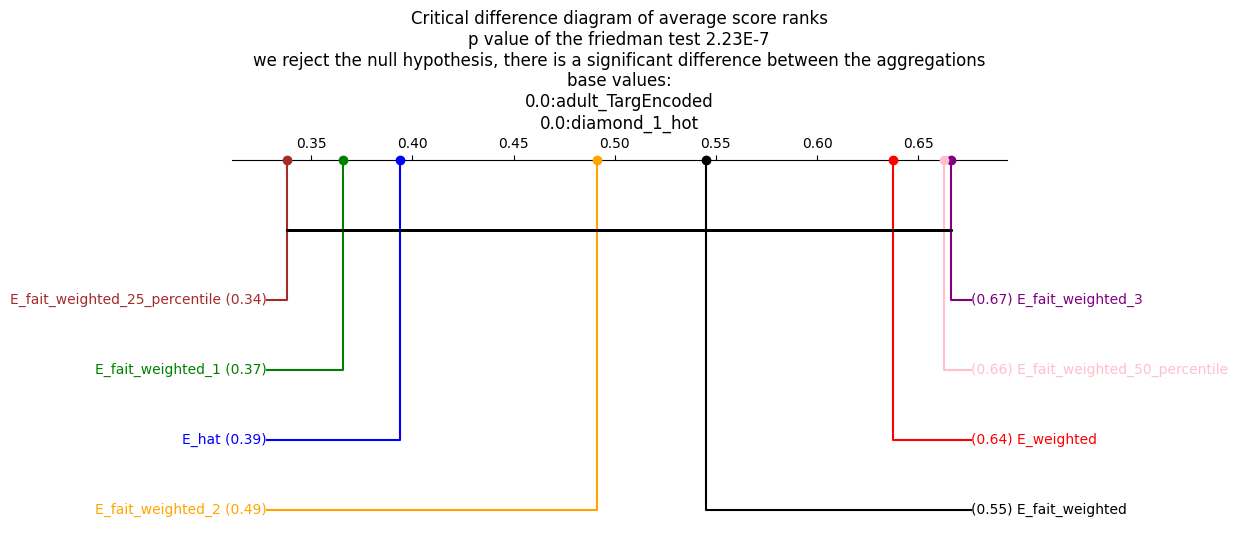

imb_5.0
['008_imb_5.0' '004_imb_5.0']


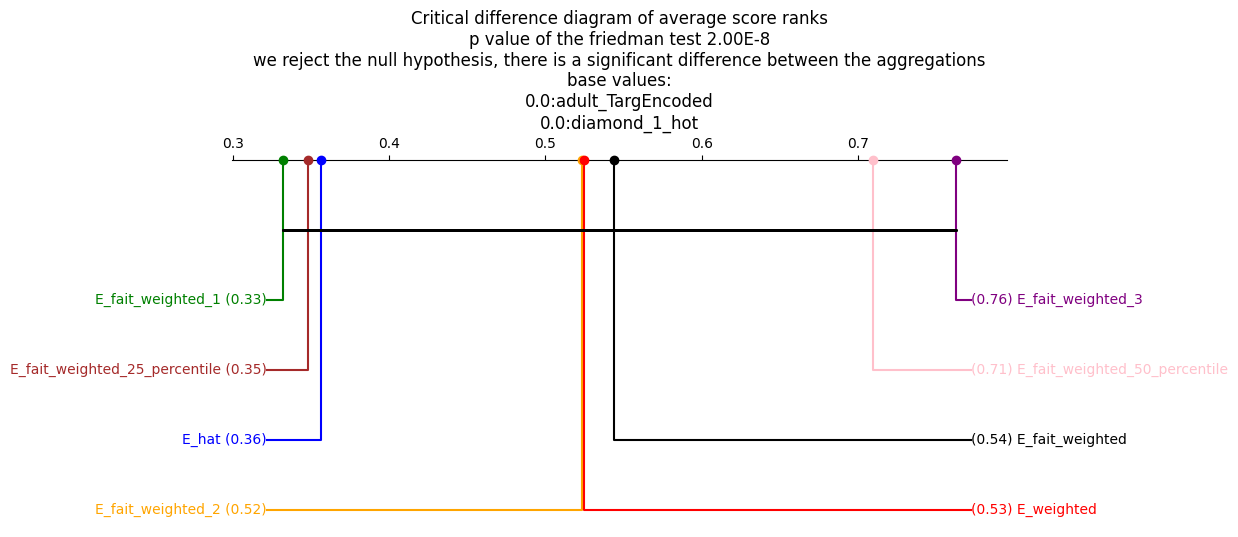

imb_0.99
['008_imb_0.99' '004_imb_0.99']


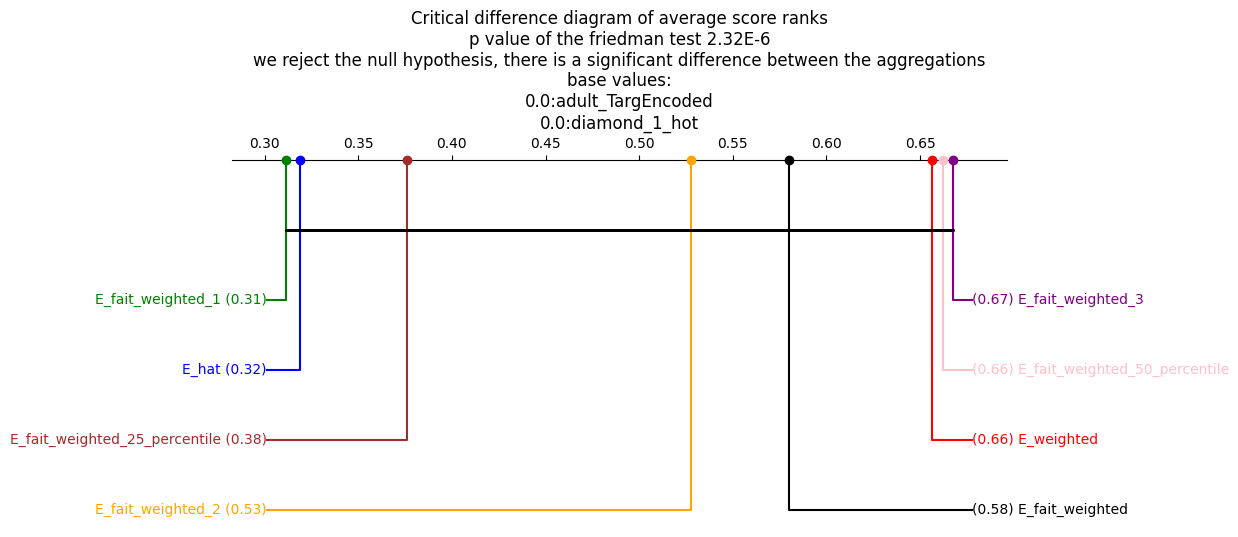

In [6]:
# using scipy_posthoc to draw the CD diagram
import scikit_posthocs as sp
import scipy.stats as ss
from decimal import Decimal

colors = {"E_hat":"blue","E_fait_weighted_1":"green","E_weighted":"red","E_fait_weighted_2":"orange","E_fait_weighted_3":"purple","E_fait_weighted":"black","E_fait_weighted_25_percentile":"brown",
"E_fait_weighted_50_percentile":"pink"}


def draw_critical_difference_diagram(dataframe_ranks,bv,datasets):
    # compute the ranks for the friedman test
    test_ranks = {}
    for name, group in dataframe_ranks.groupby("aggregation"):
        test_ranks[name] = group["delta"].values
    _, p = ss.friedmanchisquare(*test_ranks.values())
    
    # Convert p-value to scientific notation
    p_str = "{:.2E}".format(Decimal(str(p)))
    title = "p value of the friedman test "+p_str

    if p < 0.05:
        title += "\nwe reject the null hypothesis, there is a significant difference between the aggregations"
    else:
        print(bv,datasets)
        title += "\nwe accept the null hypothesis, there is no significant difference between the aggregations"#+([str((np.round(b,2)))+":"+dtn for b,dtn in zip(bv,datasets)])
        print(title)
        return
    #print(dataframe_ranks.columns,"columns")
    # join the eperimental setting and the dataset in the same column named "dataset"
    dataframe_ranks["dataset"] = dataframe_ranks["experimental setting"] + " " + dataframe_ranks["dataset"]
    # delete the old columns
    dataframe_ranks = dataframe_ranks.drop(columns=["experimental setting","base value"])
    #print(dataframe_ranks.columns,"columns")
    avg_rank = dataframe_ranks.groupby(["dataset"]).delta.rank(pct=True).groupby(dataframe_ranks.aggregation).mean()

    
    #print(avg_rank,"avg rank")
    #print(test_ranks.values(),"test ranks")
    test_results = sp.posthoc_conover_friedman(
        dataframe_ranks,
        melted=True,
        block_col='dataset',
        group_col='aggregation',
        y_col='delta',
    )

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5), dpi=100)
    combination = "base values:\n"+"\n".join([str((np.round(b,2)))+":"+dtn for b,dtn in zip(bv,datasets)])
    plt.title('Critical difference diagram of average score ranks\n' + title+"\n"+combination)
    sp.critical_difference_diagram(avg_rank, test_results, ax=ax,color_palette=colors)

    #plt.savefig("critical_difference_diagram"+str(np.round(bv,2))+".pdf")
    plt.show()
    plt.clf()
    plt.close()
# iterate over the base values



# in order to compute the tests, compute it based on every combination of base values for each dataset
distributions = ['iid','imb_5.0','imb_0.99']
for i,(bv1,bv2) in enumerate(base_values_combinations):

    # select the rows with the base value
    #print(bv1,bv2)
    # select the rows with the base value bv1 of the dataset
    dt1 = df_ranks_copy[df_ranks_copy["dataset"]==dataset_names[0]]
    #dt1 = dt1[dt1["base value"]==bv1]
    # select the rows with the base value bv2 of the dataset
    dt2 = df_ranks_copy[df_ranks_copy["dataset"]==dataset_names[1]]
    #dt2 = dt2[dt2["base value"]==bv2]
    # merge the two datasets
    dt = pd.concat([dt1,dt2])
    # now divide the dataframe based on the distribution
    for es in distributions:
        # check if the string es is in the value of the column "experimental setting"
        print(es)
        dt_es = dt[dt["experimental setting"].str.contains(es)]
        # draw the critical difference diagram
        print(dt_es["experimental setting"].unique())
        draw_critical_difference_diagram(dt_es.copy(),bv = [bv1,bv2],datasets=dataset_names)
    #print(dt)



